In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

In [3]:
from src.conexao_banco import conn, cursor

- Primeira pergunta de negócio: Quais são os locais de origem com maior número de solicitações?

In [4]:
query = """
    SELECT 
        "Pickup_Location", 
        COUNT(*) AS quantity 
    FROM ncr_ride_bookings 
    GROUP BY "Pickup_Location" 
    ORDER BY count(*) DESC
"""

In [5]:
contagem_localizacoes_origem = pd.read_sql_query(query, conn)

C:\Users\Victor\AppData\Local\Temp\ipykernel_21788\2466399021.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  contagem_localizacoes_origem = pd.read_sql_query(query, conn)


In [6]:
contagem_localizacoes_origem

,Pickup_Location,quantity
0,Khandsa,947
1,Barakhamba Road,939
2,Saket,929
3,Badarpur,912
4,Pragati Maidan,912
...,...,...
171,Bahadurgarh,791
172,Laxmi Nagar,789
173,Ashok Vihar,784
174,Chirag Delhi,784


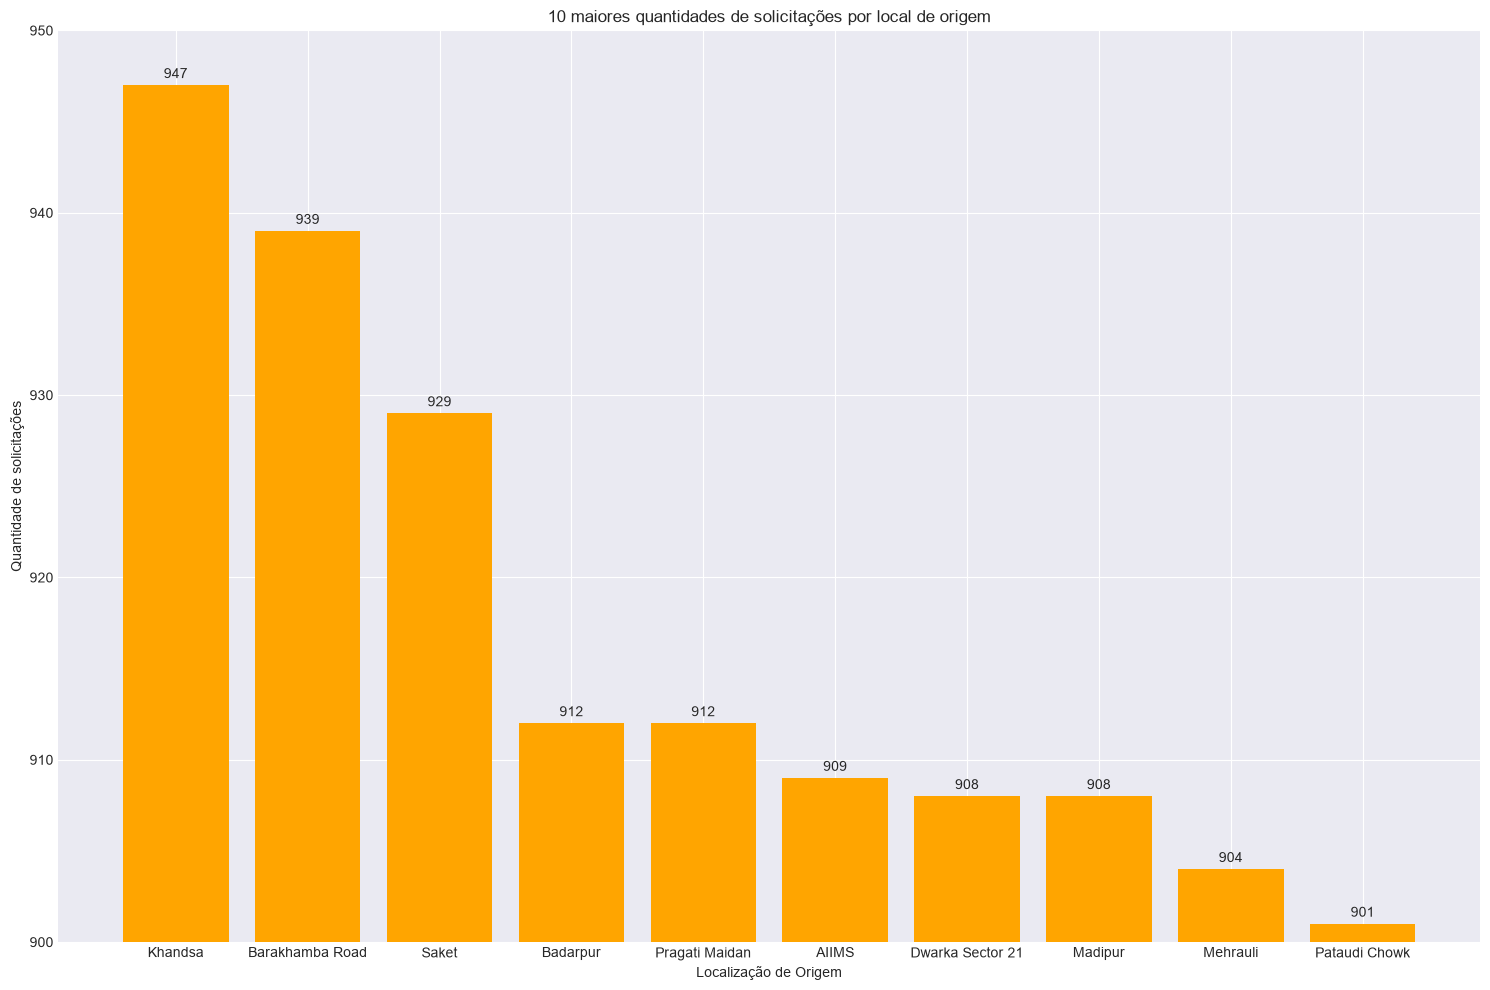

In [7]:
plt.figure(figsize=(15, 10))
plt.style.use('seaborn-v0_8-darkgrid')

barras = plt.bar(contagem_localizacoes_origem['Pickup_Location'].head(10), contagem_localizacoes_origem['quantity'].head(10), color='Orange')

plt.bar_label(barras, padding=3)

plt.xlabel("Localização de Origem")
plt.ylim(900, 950)
plt.ylabel("Quantidade de solicitações")
plt.title("10 maiores quantidades de solicitações por local de origem")
plt.tight_layout()
plt.show()

    Dentre os locais de origem com maiores números de solicitações, os 5 que mais se destacam são: Khandsa com 947 solicitações, Barakhamba Road com 939 solicitações, Saket com 929 solicitações, Badarpur e Pragati Maidan ambos com 912 solicitações.

- Segunda pergunta de negócio: Quais são os destinos mais frequentes?

In [8]:
query = """
    SELECT 
        "Drop_Location", 
        COUNT(*) as quantity 
    FROM ncr_ride_bookings 
    GROUP BY "Drop_Location" 
    ORDER BY COUNT(*) DESC
"""

In [9]:
destinos_frequencia = pd.read_sql_query(query, conn)

C:\Users\Victor\AppData\Local\Temp\ipykernel_21788\3534584623.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  destinos_frequencia = pd.read_sql_query(query, conn)


In [10]:
destinos_frequencia

,Drop_Location,quantity
0,Ashram,930
1,Basai Dhankot,911
2,Lok Kalyan Marg,909
3,Narsinghpur,908
4,Cyber Hub,908
...,...,...
171,Seelampur,795
172,Bhiwadi,787
173,Shivaji Park,784
174,Anand Vihar ISBT,776


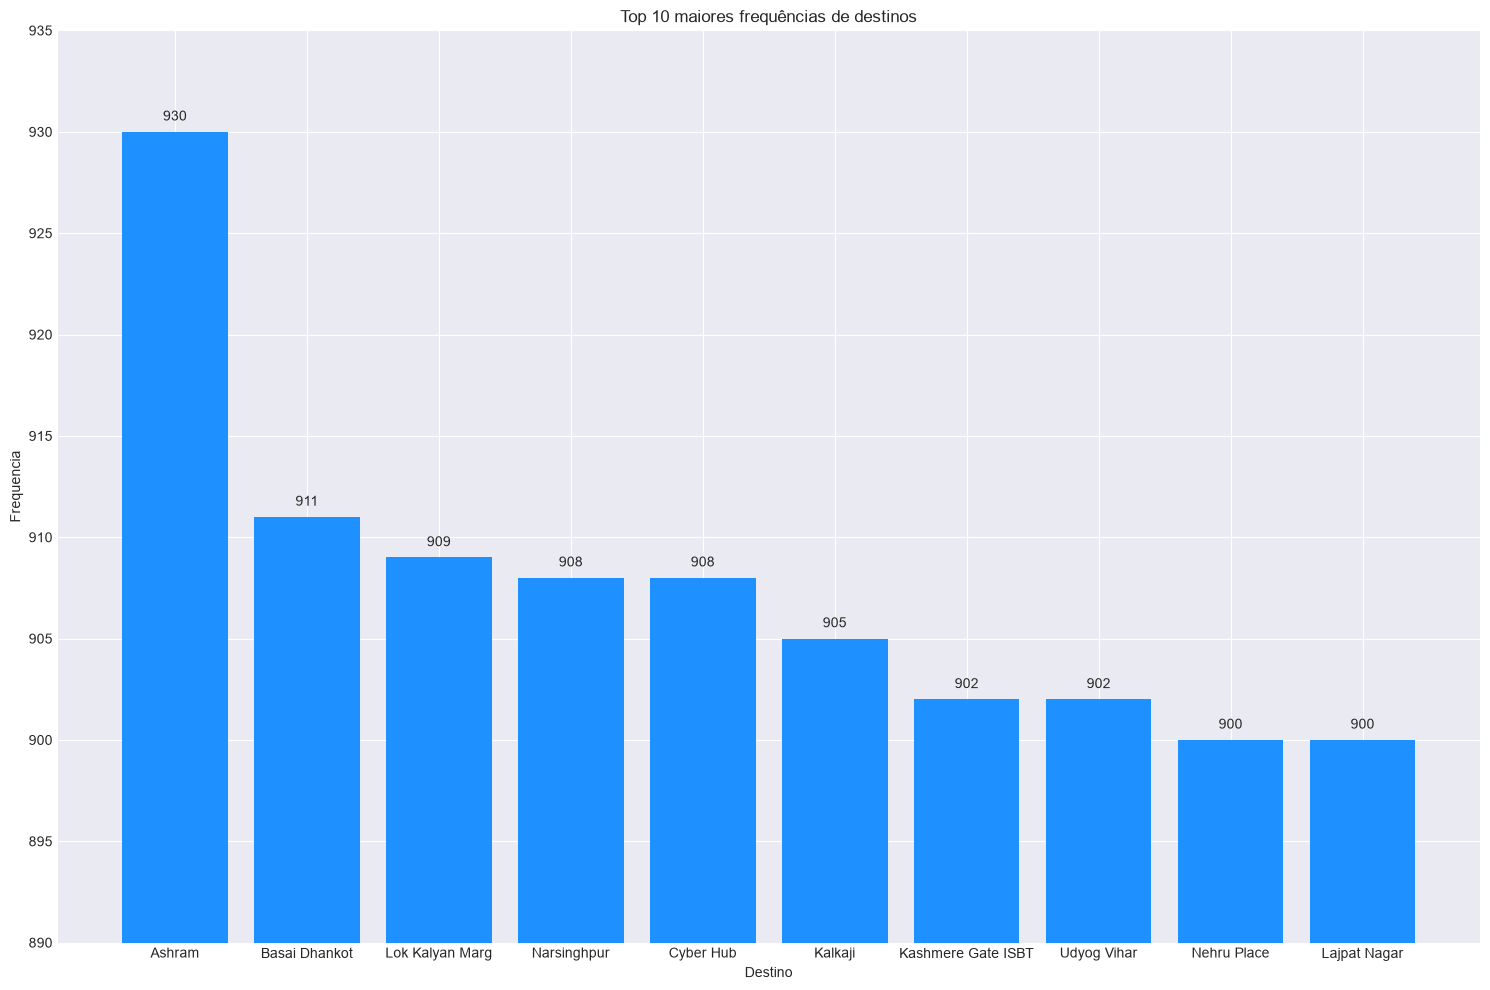

In [11]:
plt.figure(figsize=(15, 10))

barras = plt.bar(destinos_frequencia['Drop_Location'].head(10), destinos_frequencia['quantity'].head(10), color='dodgerblue')

plt.bar_label(barras, padding=6)

plt.xlabel('Destino')
plt.ylim(890, 935)
plt.ylabel('Frequencia')
plt.title('Top 10 maiores frequências de destinos')
plt.tight_layout()
plt.show()

    Dentre os destinos com maiores números de corridas registradas, os 5 que mais se destacam são: Ashram, com 930 corridas, Basai Dhankot, com 911 corridas, Lok Kalyan Marg, com 909 corridas, e Narsinghpur e Cyber Hub, ambos com 908 corridas. Dessa forma, Ashram se destaca como o destino mais frequente entre os registros analisados.

- Terceira pergunta de negócio: Quais locais de origem apresentam o maior valor médio por corrida concluída?

In [12]:
query = """
    SELECT 
        "Pickup_Location", 
        ROUND(AVG("Booking_Value")::numeric, 2) as average_value 
    FROM ncr_ride_bookings 
    WHERE "Booking_Status" = 'Completed' 
    GROUP BY "Pickup_Location" 
    ORDER BY AVG("Booking_Value") DESC   
    LIMIT 10
"""

In [13]:
local_valor_medio = pd.read_sql_query(query, conn)

C:\Users\Victor\AppData\Local\Temp\ipykernel_21788\2973083949.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  local_valor_medio = pd.read_sql_query(query, conn)


In [14]:
local_valor_medio

,Pickup_Location,average_value
0,Greater Noida,557.72
1,Pataudi Chowk,550.74
2,Anand Vihar ISBT,544.02
3,Tughlakabad,541.26
4,Kherki Daula Toll,541.22
5,Rohini West,540.32
6,Udyog Vihar,539.90
7,Paharganj,538.71
8,Dilshad Garden,538.10
9,Arjangarh,538.03


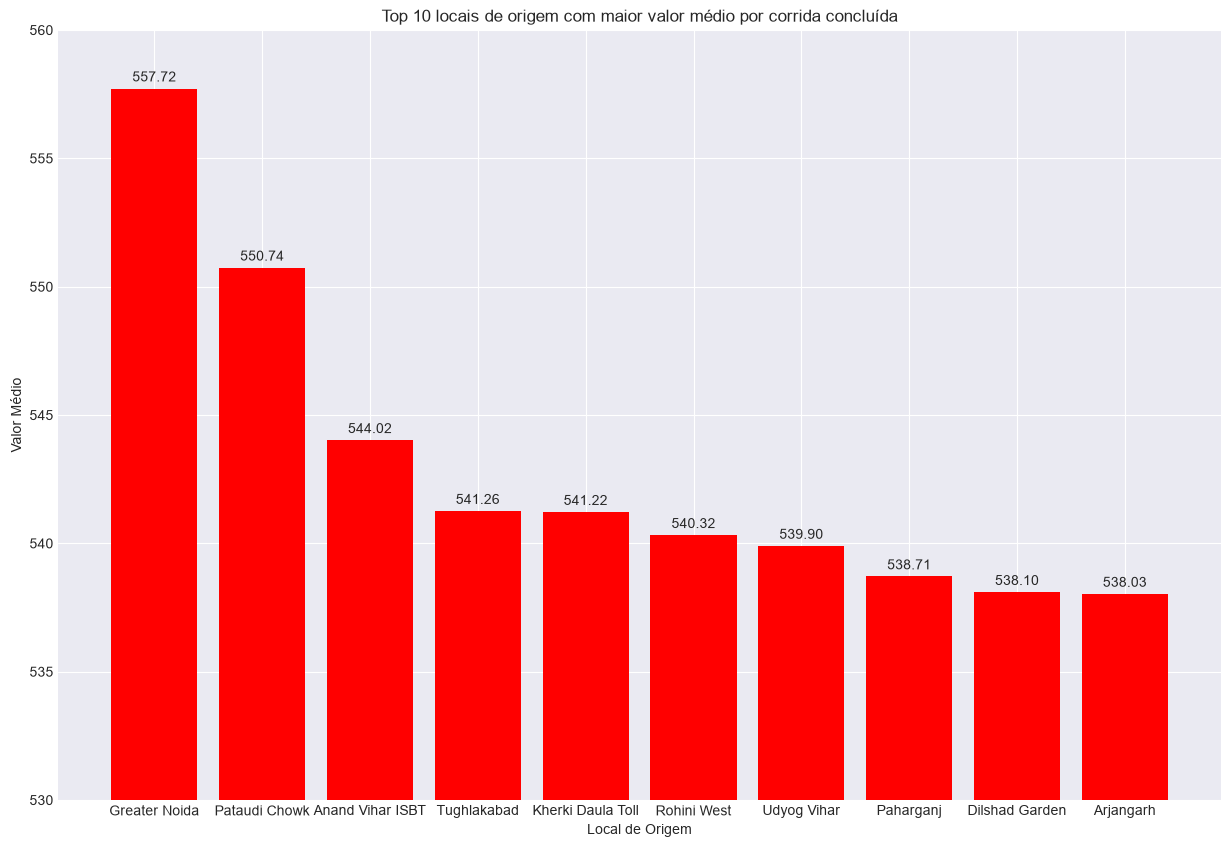

In [15]:
plt.figure(figsize=(15, 10))

barras = plt.bar(local_valor_medio['Pickup_Location'], local_valor_medio['average_value'], color='red')

plt.bar_label(barras, padding=3, fmt='%.2f')

plt.xlabel('Local de Origem')
plt.ylim(530, 560)
plt.ylabel('Valor Médio')
plt.title('Top 10 locais de origem com maior valor médio por corrida concluída')

plt.show()

    Dentre os locais de origem com os maiores valores médios por corrida concluída, os 5 que mais se destacam são: Greater Noida, com valor médio de 557,72, Pataudi Chowk, com 550,74, Anand Vihar ISBT, com 544,02, Tughlakabad, com 541,26, e Kherki Daula Toll, com 541,22. Dessa forma, Greater Noida se destaca por apresentar o maior valor médio por corrida concluída entre os locais analisados.

- Quarta pergunta de negócio: Quais locais de origem apresentam a maior taxa de cancelamento?

In [16]:
query = """
    SELECT 
        "Pickup_Location",
        ROUND(
            100 * COUNT(*) FILTER(
                WHERE "Booking_Status" IN ('Cancelled by Customer', 'Cancelled by Driver')
                ) / COUNT(*)::numeric, 2) as cancellation_rate
    FROM ncr_ride_bookings
    GROUP BY "Pickup_Location" 
    ORDER BY cancellation_rate  DESC
    LIMIT 10
"""

In [17]:
local_taxa_cancelamento = pd.read_sql_query(query, conn)

C:\Users\Victor\AppData\Local\Temp\ipykernel_21788\2691504775.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  local_taxa_cancelamento = pd.read_sql_query(query, conn)


In [18]:
local_taxa_cancelamento

,Pickup_Location,cancellation_rate
0,Vinobapuri,29.58
1,Akshardham,29.58
2,Qutub Minar,28.55
3,Munirka,28.36
4,Kadarpur,28.06
5,Faridabad Sector 15,27.88
6,Shahdara,27.61
7,Nehru Place,27.61
8,Chhatarpur,27.60
9,Karkarduma,27.54


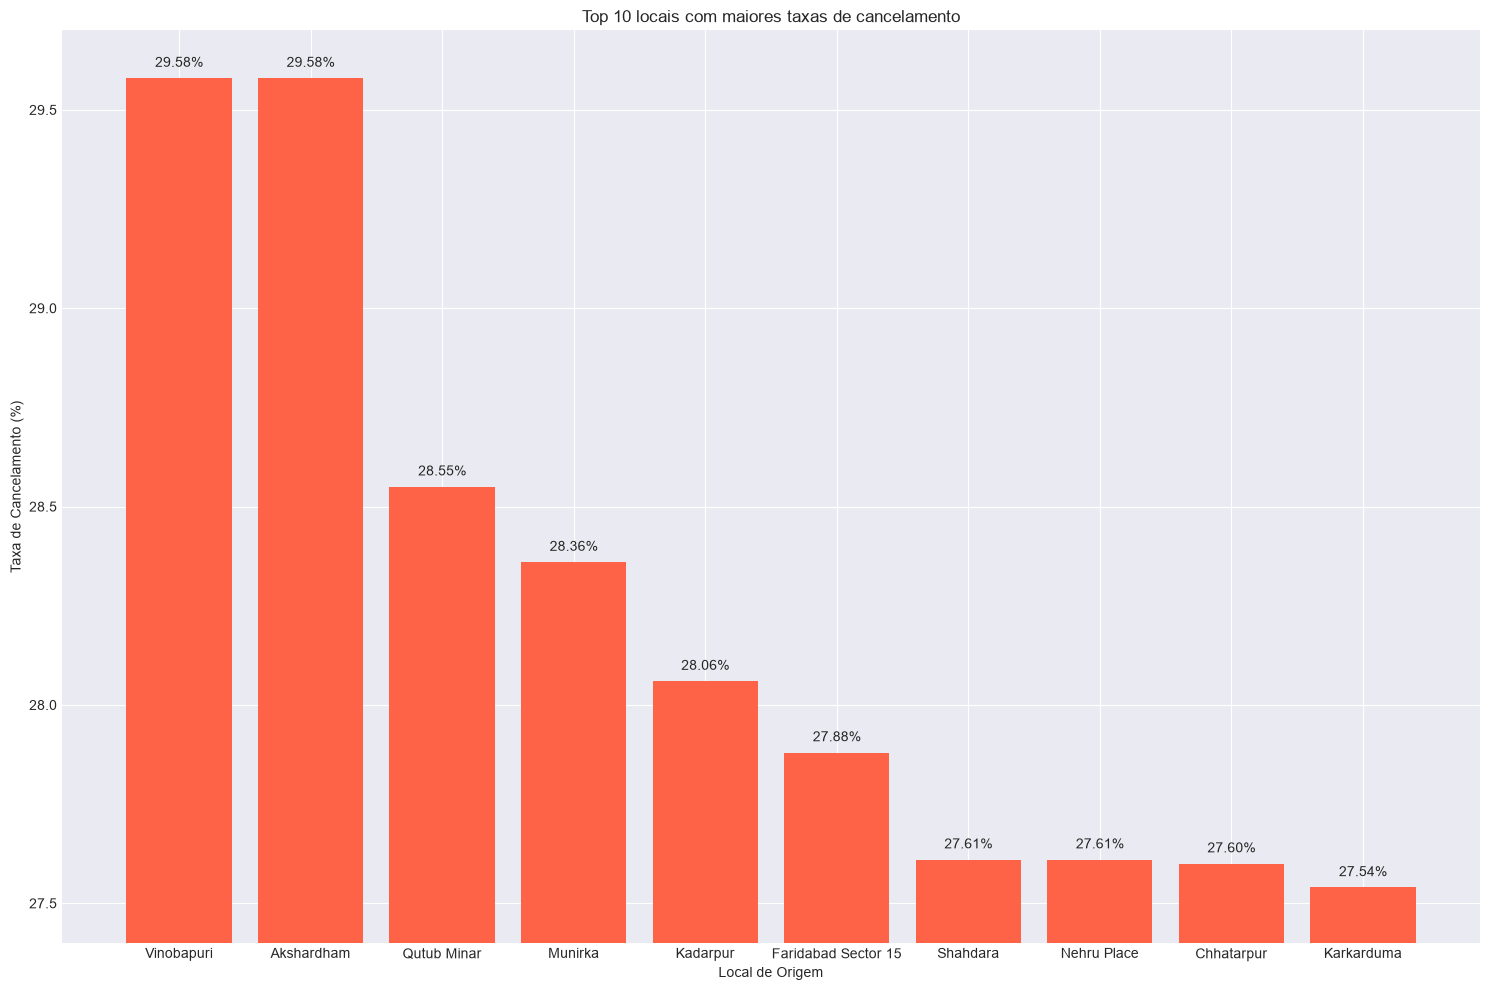

In [19]:
plt.figure(figsize=(15, 10))

barras = plt.bar(
    local_taxa_cancelamento['Pickup_Location'],
    local_taxa_cancelamento['cancellation_rate'],
    color='tomato'
)

plt.bar_label(barras, padding=6, fmt='%.2f%%')

plt.xlabel('Local de Origem')
plt.ylim(27.4, 29.7)
plt.ylabel('Taxa de Cancelamento (%)')
plt.title('Top 10 locais com maiores taxas de cancelamento')

plt.tight_layout()
plt.show()

    Dentre os locais de origem com as maiores taxas de cancelamento, os 5 que mais se destacam são: Vinobapuri e Akshardham, ambos com 29,58%, Qutub Minar, com 28,55%, Munirka, com 28,36%, e Kadarpur, com 28,06%. Dessa forma, Vinobapuri e Akshardham apresentam as maiores taxas de cancelamento entre os locais analisados, indicando uma maior proporção de corridas canceladas nessas regiões.